# First image through an Endpoint

Run this notebook on your **laptop**. It calls Sana, an open text-to-image model, running on a GPU as a Nebius Serverless AI Endpoint.

You'll generate an image, then run four small experiments that show what stays the same between generations and what doesn't. You're done when the images and your notes are on your laptop and the Endpoint is no longer `RUNNING`.

> The Endpoint bills from the moment it starts until you stop it, idle or not. Create it right before you run this notebook, and finish with the last cell.

Guide: [02-first-generation.md](../02-first-generation.md). Setup (account, credits, `uv`): the **Setup** section of the [module README](../README.md).

## 1. Connect to your Endpoint

Create the Endpoint in the web console first (see the guide). Then run this cell. It reads `code/.env` and the environment, and asks only for what is still missing: the HTTPS URL and the token.

The answers are saved to `code/.env` (readable only by you, and ignored by Git). To be asked again, delete those lines and restart the kernel.

The token is typed with `getpass`, so it is never echoed. Treat it like a password: don't paste it into a cell, a screenshot or a chat.

In [3]:
import sys
import time
from pathlib import Path

from IPython.display import Image, display

MODULE = "01-consistent-media-generation-on-serverless-gpus"
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
found = [p for p in candidates if (p / "common.py").is_file()]
assert found, "Open this notebook from the repository (its code/ folder)"
CODE = found[0].resolve()
sys.path.insert(0, str(CODE))

import importlib

import image

importlib.reload(image)  # this kernel may already have imported image.py
from common import asset_record, output_dir, setup_endpoint, wait_ready
from image import ImageGenerator, cached_image, image_comparison, share_card

BASE_URL, TOKEN = setup_endpoint()


Endpoint configured (***npDL)


## 2. Wait until it's ready

`RUNNING` in the console means the container started, not that the model is loaded. Until the server has downloaded and loaded the weights, calls return `502`.

This cell polls `/v1/models` every 2 seconds until the model answers. It gives up after 10 minutes; re-running it is safe.

In [4]:
start = time.perf_counter()
models = wait_ready(BASE_URL, TOKEN, deadline_s=600)
print("Served models:", [m.get("id") for m in models["data"]])
print(f"Ready after {time.perf_counter() - start:.0f} s of waiting")

Served models: ['Efficient-Large-Model/Sana_1600M_1024px_diffusers']
Ready after 0 s of waiting


## 3. Generate an image

One POST to `/v1/images/generations`. The body is the model, the prompt, and the settings. The token goes in the `Authorization` header. The response is a PNG, base64-encoded in `data[0].b64_json`.

Change the prompt if you like. Keep it free of real people, brands and known characters. Each side of `size` must be a multiple of 32.

There is no seed in this request. The server picks one, so every run of the cell generates a new image.

If `REQUESTS_CA_BUNDLE` is set, `requests` uses that file instead of the public CAs. This call passes the public bundle.


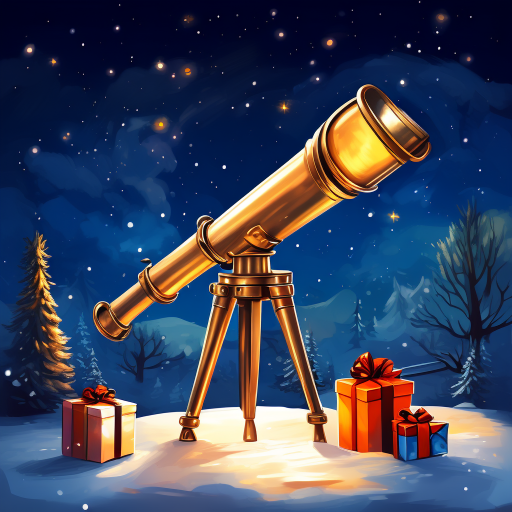

In [5]:
import base64

import certifi
import requests

prompt = (
    "A storybook illustration of a brass telescope glowing on snow under a starry night sky, "
    "a small decorated tree and wrapped presents, warm colors, no people, no text"
)

request_data = {
    "model": "Efficient-Large-Model/Sana_1600M_1024px_diffusers",
    "prompt": prompt,
    "size": "512x512",
    "response_format": "b64_json",
}

response = requests.post(
    f"{BASE_URL}/v1/images/generations",
    headers={"Authorization": f"Bearer {TOKEN}"},
    json=request_data,
    timeout=300,
    verify=certifi.where(),
)
response.raise_for_status()
png = base64.b64decode(response.json()["data"][0]["b64_json"])
display(Image(data=png))


`ImageGenerator` posts the same kind of request, saves the PNG, and returns the path. Its default seed is 7, so the experiments below can repeat an image. Each call is one line.


Generated in 1.2 s
Saved /Users/mnrozhkov/dev/course_media_agent/production-ai-agents-for-media-generation/01-consistent-media-generation-on-serverless-gpus/code/runs/first-image.png


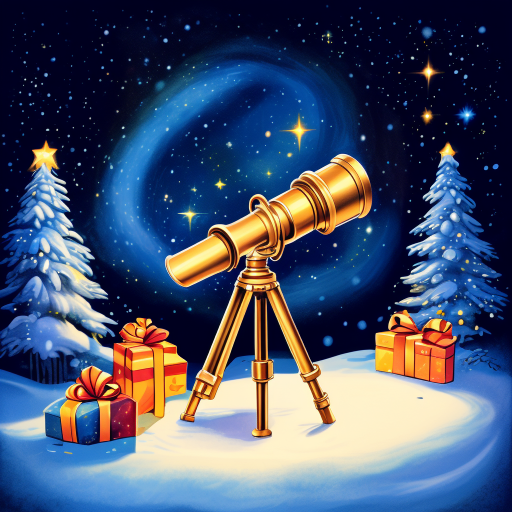

In [6]:
prompt = (
    "A storybook illustration of a brass telescope glowing on snow under a starry night sky, "
    "a small decorated tree and wrapped presents, warm colors, no people, no text"
)

generator = ImageGenerator(BASE_URL, TOKEN)
out = generator.generate_image(prompt)
print("Saved", out)
display(Image(filename=str(out)))

## 4. Same settings, same image

Generate the same image three times with exactly the same settings. Then compare the hashes. With the same prompt, seed and settings on the same Endpoint, are the three images byte-identical?


Generated in 1.2 s
Generated in 1.2 s
Generated in 1.2 s
Hashes: ['6dd0a6ff2029', '6dd0a6ff2029', '6dd0a6ff2029'] | identical: True


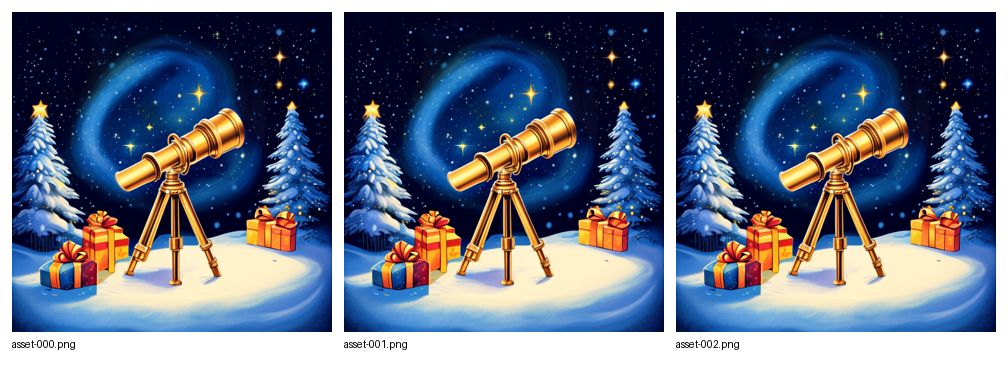

In [7]:
folder = output_dir(None)
paths = [
    generator.generate_image(prompt, out=folder / f"asset-{index:03d}.png", seed=7)
    for index in range(3)
]
hashes = [asset_record(path)["sha256"] for path in paths]
print("Hashes:", [h[:12] for h in hashes], "| identical:", len(set(hashes)) == 1)
display(Image(data=image_comparison(paths)))


## 5. Leave out the seed

Same prompt and settings, but no seed: the server picks a random one for every call. Two calls, two different images. A seed you didn't record is a setting you can't repeat.

Generated in 1.2 s
Generated in 1.2 s


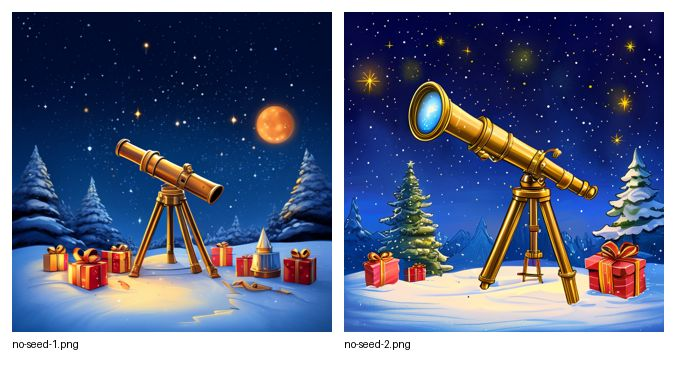

Identical: False


In [8]:
no_seed = []
for i in (1, 2):
    path = generator.generate_image(prompt, out=folder / f"no-seed-{i}.png", seed=None)
    no_seed.append(asset_record(path))

display(Image(data=image_comparison([folder / a["file"] for a in no_seed])))

print("Identical:", no_seed[0]["sha256"] == no_seed[1]["sha256"])

## 6. The seed is a setting

Now a character: the same description goes into every prompt below. First, the same scene with seed 7 and seed 8. The seed changes the picture as much as any other setting does.

`cached_image` is the helper for every image after this. It hashes the model, prompt and seed into the file name. If that PNG is already in your run folder, it skips the Endpoint. Re-run the cell: you only wait when one of those three changed.

Before you go on, look at the seed-7 image: does it show the scarf and the spectacles? If Sana skips a trait even here, don't count it in step 7.


Generated in 1.2 s
Generated in 1.5 s


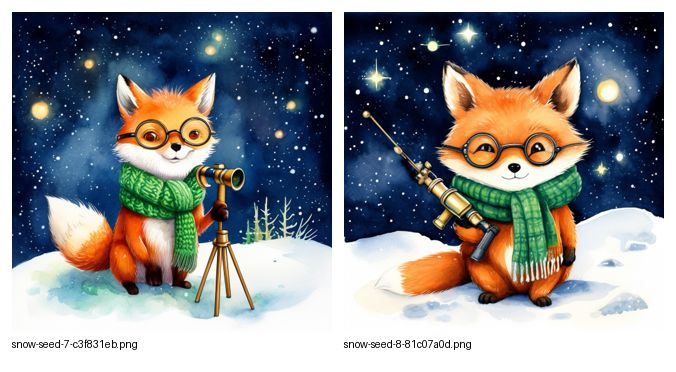

In [9]:
CHARACTER = (
    "a small red fox with a white chest, round brass spectacles and a green knitted scarf, "
    "holding a brass telescope; watercolor storybook illustration, soft painterly texture, no text"
)
scenes = {
    "snow": f"{CHARACTER}. The fox sits in the snow under a starry night sky.",
    "beach": f"{CHARACTER}. The fox sits on a sunny beach by the sea.",
}


def generate_image(prompt, seed=7, label="image", **settings):
    request = {"model": generator.model, "prompt": prompt, "seed": seed, **settings}
    path = folder / f"{label}-{image.request_id(**request)}.png"
    if not path.exists():
        generator.generate_image(prompt, out=path, seed=seed, **settings)
    return path


def compare_images(paths):
    display(Image(data=image_comparison(paths)))


images = [
    generate_image(scenes["snow"], seed=7, label="snow-seed-7"),
    generate_image(scenes["snow"], seed=8, label="snow-seed-8"),
]
compare_images(images)


## 7. Same character, new scene

Same character description, same seed, a different scene. Compare the two foxes: which traits survived, and which changed?

A prompt describes a character. It does not hold one fixed. Keeping a character across scenes takes more than a prompt and a seed. You will try this yourself in *Practice*, then write what you saw in *Your notes*.


Generated in 1.3 s


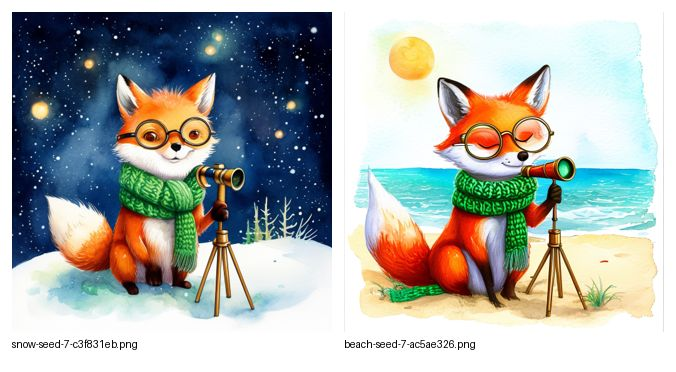

In [10]:
images = [
    generate_image(scenes["snow"], seed=7, label="snow-seed-7"),
    generate_image(scenes["beach"], seed=7, label="beach-seed-7"),
]
compare_images(images)


## Inspiration

Four more subjects. Each one repeats steps 6 and 7: two seeds in one scene, then the same seed in a new scene. Optional. Running a cell calls the Endpoint.


### Astronaut cat

A character in a costume. Moon, then a sofa. Check whether the helmet and the backpack survive the move.


Generated in 1.2 s
Generated in 1.2 s


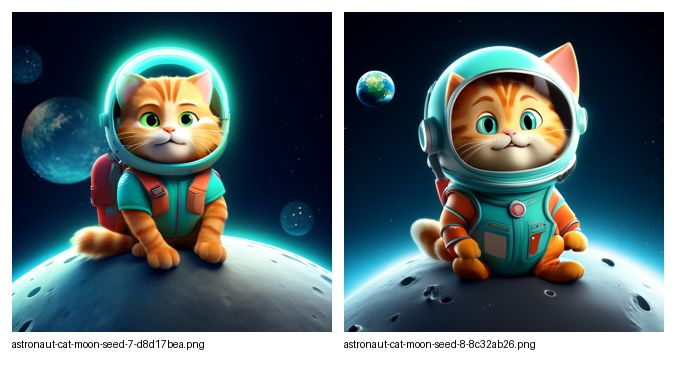

In [11]:
CAT = (
    "a round orange tabby cat with a white muzzle, wearing a teal spacesuit, "
    "a clear round helmet and a small red backpack; "
    "playful 3D animated film illustration, soft lighting, no text"
)
cat_scenes = {
    "moon": f"{CAT}. The cat sits on a moon rock, with Earth in the dark sky.",
    "sofa": f"{CAT}. The cat sits on a cozy living-room sofa beside a sleeping dog.",
}


# Different seeds, same scene.
images = [
    generate_image(cat_scenes["moon"], seed=7, label="astronaut-cat-moon-seed-7"),
    generate_image(cat_scenes["moon"], seed=8, label="astronaut-cat-moon-seed-8"),
]
compare_images(images)


### Catalog mug

A product, not a character. Two seeds on white, then the same seed on white and pale blue. Check whether the handle and the lid stay the same mug.


Generated in 1.1 s
Generated in 1.0 s


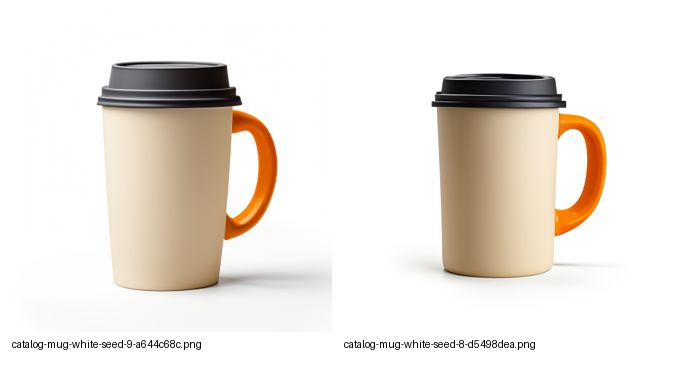

In [12]:
PRODUCT = (
    "one matte cream-colored reusable coffee mug with a cylindrical body, "
    "a large orange C-shaped handle and a dark charcoal lid; "
    "photorealistic product photography, front three-quarter view, "
    "soft studio lighting, subtle contact shadow, no logo, no text"
)
product_scenes = {
    "white": f"{PRODUCT}. The mug stands on a seamless white studio background.",
    "blue": f"{PRODUCT}. The mug stands on a seamless pale-blue studio background.",
}


# Different seeds: does the model invent different versions of the product?
images = [
    generate_image(product_scenes["white"], seed=9, label="catalog-mug-white-seed-9"),
    generate_image(product_scenes["white"], seed=8, label="catalog-mug-white-seed-8"),
]
compare_images(images)


### Christmas card

A holiday character and one gift. Workshop, then a doorstep. The prompt leaves the upper quarter empty, so a greeting could sit there.


Generated in 1.2 s
Generated in 1.1 s


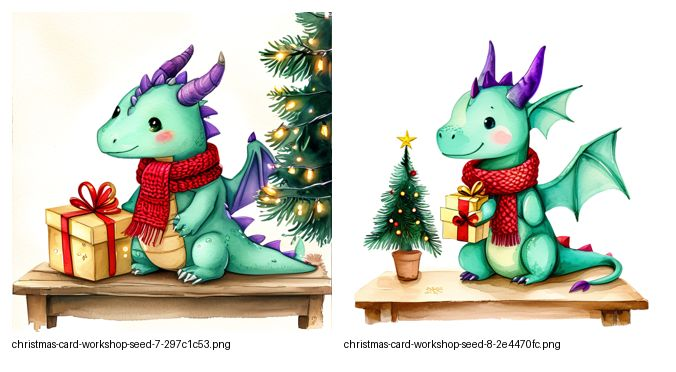

In [13]:
CHRISTMAS_DRAGON = (
    "a small mint-green dragon with short purple horns, "
    "wearing a red knitted scarf, holding one golden gift box "
    "tied with a wide red ribbon; "
    "charming watercolor Christmas card illustration, "
    "soft paper texture, warm gentle colors, no text"
)

christmas_scenes = {
    "workshop": (
        f"{CHRISTMAS_DRAGON}. The dragon sits at a wooden wrapping table "
        "beside a small Christmas tree with warm fairy lights. "
        "Simple uncluttered composition, upper quarter mostly empty ivory paper."
    ),
    "doorstep": (
        f"{CHRISTMAS_DRAGON}. The dragon stands outside a cozy cottage door "
        "in gently falling snow, warm light spilling from the window. "
        "Simple uncluttered composition, upper quarter mostly empty ivory paper."
    ),
}


# Choose your favorite interpretation.
images = [
    generate_image(christmas_scenes["workshop"], seed=7, label="christmas-card-workshop-seed-7"),
    generate_image(christmas_scenes["workshop"], seed=8, label="christmas-card-workshop-seed-8"),
]
compare_images(images)


## Practice

Your subject. Three steps, and each step changes one thing. Change the quoted lines, then run. The quotes start as a fox, so a run with no edits still produces images.

Keep the text free of real people, brands and known characters. The Endpoint has to be `RUNNING`.


### 1. One character, one scene

Look at the image before step 2. Count only the traits you can see. A trait the model skipped here was never held fixed.


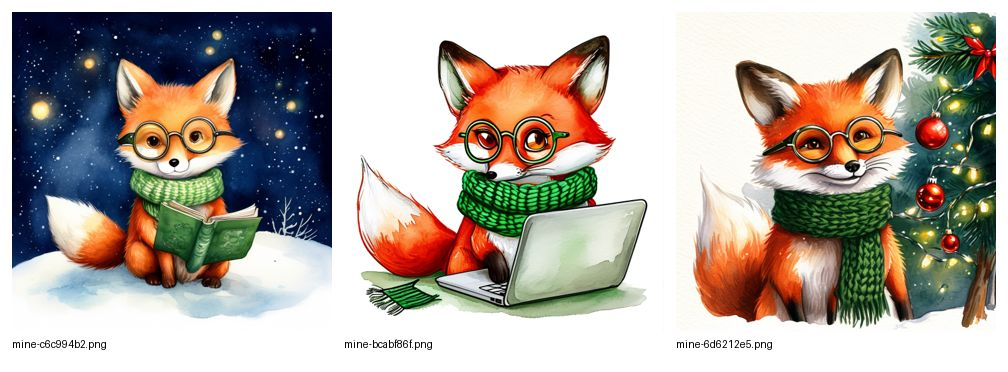

In [19]:
# Change the quoted lines, then run.
TITLE = "Christmas Greetings Cards Factory"  # e.g. Add you title here
SUBJECT = "a small red fox with a white chest, round brass spectacles and a green knitted scarf"
STYLE = "watercolor storybook illustration, soft painterly texture, no text"
# SCENE_A = ""

scenes = {
    "scene_1": f"{SUBJECT}. Sits in the snow under a starry night sky, holding a brass telescope",
    "scene_2": f"{SUBJECT}. Sitting in front of the laptop, and learning Media Generation course with DTC and Nebius.",
    "scene_3": f"{SUBJECT}. Decorating the home for christmas with Christmas lights and a Christmas tree.",
}

SEED = 7


my_images = [
    generate_image(f"{scenes[scene]} {STYLE}", SEED, label="mine", size="512x512")
    for scene in scenes
]
compare_images(my_images)


## A card to share

`share_card` builds one picture from the three Practice images. A line break in the headline is a line break on the card. The file is saved in your run folder.


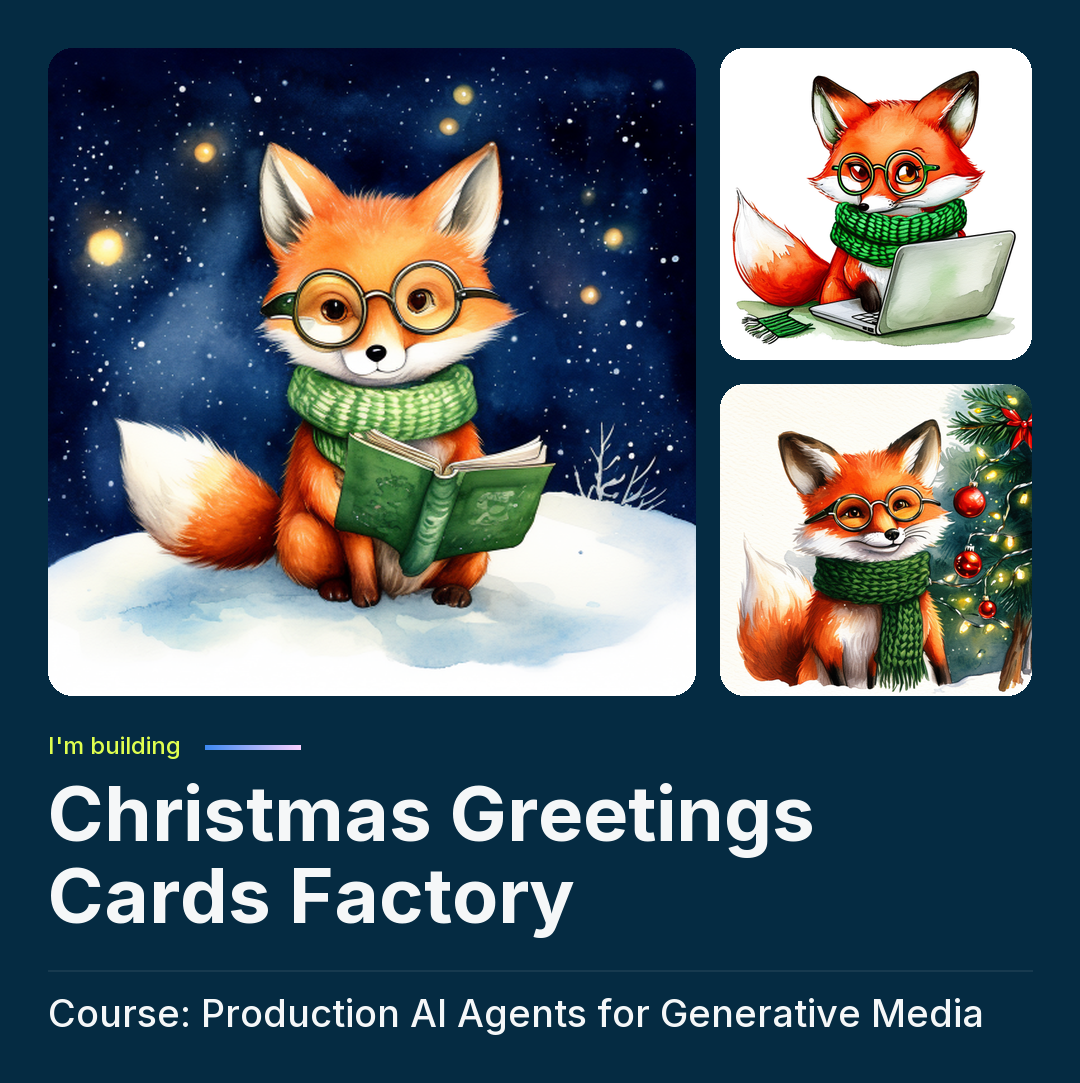

In [20]:
# A line break in the string is a line break on the card.
import importlib
import image


card = share_card(my_images, TITLE, out=folder / "share-card.png")
display(Image(filename=str(card)))


## 8. Stop the Endpoint

Do it now: open the Endpoint in the [web console](https://console.nebius.com/), click **Stop** (or **Delete**), and check that its status is `STOPPED`.

- **Stop** keeps the Endpoint and its URL; start it again later. Nothing bills for compute while it's stopped.
- **Delete** removes it. A new Endpoint gets a new URL and token. Delete `BASE_URL` and `TOKEN` from `code/.env`, restart the kernel, and run step 1 again.

You're done when:

- [ ] `runs/first-image.png` shows your image.
- [ ] Your run folder has the images from steps 4 to 7 and from Practice.
- [ ] You've answered the four questions in *Your notes*.
- [ ] Your run folder has `share-card.png`, the picture you'd post.
- [ ] The Endpoint is `STOPPED` or deleted.
